<a href="https://colab.research.google.com/github/enrifonseca/AprendizajeAutomatico1/blob/main/Lecci%C3%B3n_introducci%C3%B3n_a_la_unidad_9_Ejemplo_en_sklearn.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [62]:
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score


In [63]:
# 1. Cargar los datos (ya son numéricos)
vinos = load_wine()
X, y = vinos.data, vinos.target

In [64]:
# 2. Dividir en entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

In [65]:
# 3. Crear y entrenar el modelo de árbol de decisión (¡Sin escalar X!)
arbol = DecisionTreeClassifier(max_depth=3, random_state=42)
arbol.fit(X_train, y_train)

DecisionTreeClassifier(max_depth=3, random_state=42)

In [66]:
# 4. Predecir y evaluar
predicciones_arbol = arbol.predict(X_test)
precision = accuracy_score(y_test, predicciones_arbol)
print(f"Precisión del árbol de decisión: {precision:.2f}")

Precisión del árbol de decisión: 0.96


In [67]:
X.shape

(178, 13)

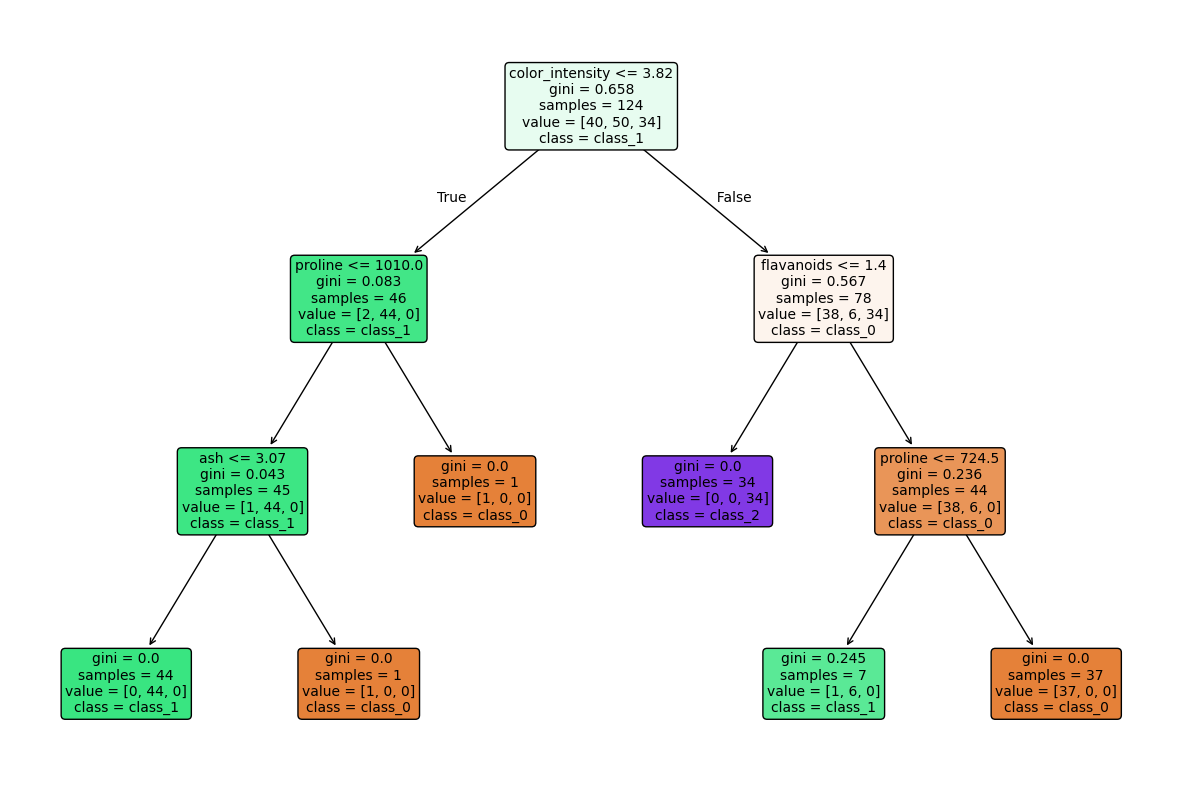

In [68]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

# Configurar el tamaño del gráfico
plt.figure(figsize=(15, 10))

# Dibujar el árbol entrenado
plot_tree(arbol,
          feature_names=vinos.feature_names,
          class_names=vinos.target_names,
          filled=True,
          rounded=True,
          fontsize=10)

# Mostrar el gráfico en pantalla
plt.show()

In [69]:
from sklearn.ensemble import RandomForestClassifier

# Usando los mismos datos de vinos de la sección anterior
bosque = RandomForestClassifier(n_estimators=100, random_state=42)
bosque.fit(X_train, y_train)

predicciones_bosque = bosque.predict(X_test)
precision_bosque = accuracy_score(y_test, predicciones_bosque)
print(f"Precisión de random forest: {precision_bosque:.2f}")

Precisión de random forest: 1.00


In [70]:
from sklearn.ensemble import AdaBoostClassifier, GradientBoostingClassifier

# AdaBoost
adaboost = AdaBoostClassifier(n_estimators=50, random_state=42)
adaboost.fit(X_train, y_train)
print(f"Precisión AdaBoost: {accuracy_score(y_test, adaboost.predict(X_test)):.2f}")

# Gradient boosting
gbc = GradientBoostingClassifier(n_estimators=100, learning_rate=0.1, random_state=42)
gbc.fit(X_train, y_train)
print(f"Precisión gradient boosting: {accuracy_score(y_test, gbc.predict(X_test)):.2f}")


Precisión AdaBoost: 0.98
Precisión gradient boosting: 0.91


In [71]:
from sklearn.ensemble import StackingClassifier
from sklearn.linear_model import LogisticRegression

# 1. Definir los estimadores base
estimadores_base = [
    ('rf', RandomForestClassifier(n_estimators=10, random_state=42)),
    ('gb', GradientBoostingClassifier(n_estimators=10, random_state=42))
]

# 2. Definir el meta-modelo (el que combinará las predicciones)
meta_modelo = LogisticRegression()

# 3. Crear y entrenar el stacking classifier
stacking = StackingClassifier(estimators=estimadores_base, final_estimator=meta_modelo)
stacking.fit(X_train, y_train)

print(f"Precisión stacking: {accuracy_score(y_test, stacking.predict(X_test)):.2f}")


Precisión stacking: 0.94


In [72]:
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split

# Re-split the wine dataset to ensure correct y_test for classification models
vinos_temp = load_wine()
X_temp, y_temp = vinos_temp.data, vinos_temp.target
X_train_wine, X_test_wine, y_train_wine, y_test_wine = train_test_split(X_temp, y_temp, test_size=0.3, random_state=123)

def evaluate_model(model_name, y_true, y_pred):
    accuracy = accuracy_score(y_true, y_pred)
    precision = precision_score(y_true, y_pred, average='weighted')
    recall = recall_score(y_true, y_pred, average='weighted')
    f1 = f1_score(y_true, y_pred, average='weighted')
    cm = confusion_matrix(y_true, y_pred)

    print(f"\n--- Evaluación del modelo: {model_name} ---")
    print(f"Accuracy: {accuracy:.2f}")
    print(f"Precision: {precision:.2f}")
    print(f"Recall: {recall:.2f}")
    print(f"F1-Score: {f1:.2f}")
    print("Matriz de Confusión:\n", cm)

# Evaluar Árbol de Decisión
evaluate_model("Árbol de Decisión", y_test_wine, predicciones_arbol)

# Evaluar Random Forest
evaluate_model("Random Forest", y_test_wine, predicciones_bosque)

# Evaluar AdaBoost
predicciones_adaboost = adaboost.predict(X_test_wine)
evaluate_model("AdaBoost", y_test_wine, predicciones_adaboost)

# Evaluar Gradient Boosting
predicciones_gbc = gbc.predict(X_test_wine)
evaluate_model("Gradient Boosting", y_test_wine, predicciones_gbc)

# Evaluar Stacking
predicciones_stacking = stacking.predict(X_test_wine)
evaluate_model("Stacking", y_test_wine, predicciones_stacking)


--- Evaluación del modelo: Árbol de Decisión ---
Accuracy: 0.35
Precision: 0.38
Recall: 0.35
F1-Score: 0.35
Matriz de Confusión:
 [[5 7 2]
 [5 8 5]
 [8 8 6]]

--- Evaluación del modelo: Random Forest ---
Accuracy: 0.37
Precision: 0.40
Recall: 0.37
F1-Score: 0.37
Matriz de Confusión:
 [[5 7 2]
 [5 8 5]
 [9 6 7]]

--- Evaluación del modelo: AdaBoost ---
Accuracy: 1.00
Precision: 1.00
Recall: 1.00
F1-Score: 1.00
Matriz de Confusión:
 [[14  0  0]
 [ 0 18  0]
 [ 0  0 22]]

--- Evaluación del modelo: Gradient Boosting ---
Accuracy: 0.98
Precision: 0.98
Recall: 0.98
F1-Score: 0.98
Matriz de Confusión:
 [[14  0  0]
 [ 0 18  0]
 [ 1  0 21]]

--- Evaluación del modelo: Stacking ---
Accuracy: 1.00
Precision: 1.00
Recall: 1.00
F1-Score: 1.00
Matriz de Confusión:
 [[14  0  0]
 [ 0 18  0]
 [ 0  0 22]]


# Los valores que arroja el ejercicio no coinciden con los obtenidos en el practico para lo cual se dio una respuesta erronea en algunas preguntas para poder avanzar.

# Actividad

1. Importa el dataset fetch_california_housing de sklearn.datasets.

2. Separa los datos en conjunto de entrenamiento (80%) y prueba (20%).

3. Entrena tres modelos diferentes para predecir el valor de la vivienda (target):

- Un árbol de decisión (DecisionTreeRegressor).

- Un random forest (RandomForestRegressor).

- Un gradient boosting (GradientBoostingRegressor).

4. Evalúa los tres modelos utilizando la métrica del error cuadrático medio (MSE - mean_squared_error de sklearn.metrics).

5. Imprime los resultados y observa cuál modelo tuvo el menor error.

¡Intenta resolverlo por tu cuenta antes de mirar las soluciones!

In [73]:
#1 Cargar el dataset

from sklearn.datasets import fetch_california_housing

housing = fetch_california_housing()
X, y = housing.data, housing.target

In [74]:
#2 Separar datos en conjunto de entrenamiento y prueba

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [77]:
#3 Entrenamiento de tres modelos diferentes
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

## DecisionTreeRegressor
arbol = DecisionTreeRegressor(random_state=42)
arbol.fit(X_train, y_train)

## RandomForestRegressor
random_forest = RandomForestRegressor(random_state=42)
random_forest.fit(X_train, y_train)

## GradientBoostingRegressor
gradient_boosting = GradientBoostingRegressor(random_state=42)
gradient_boosting.fit(X_train, y_train)

GradientBoostingRegressor(random_state=42)

In [78]:
#4 Evaluacion de resultados con metrica MSE

from sklearn.metrics import mean_squared_error

# Arbol de decision
pred_arbol = arbol.predict(X_test)
mse_arbol = mean_squared_error(y_test, pred_arbol)

# Random Forest
pred_random_forest = random_forest.predict(X_test)
mse_random_forest = mean_squared_error(y_test, pred_random_forest)

# Gradient Boosting
pred_gradient_boosting = gradient_boosting.predict(X_test)
mse_gradient_boosting = mean_squared_error(y_test, pred_gradient_boosting)

In [79]:
#5 Impresion de resultados

print(f"Árbol de Decisión - MSE: {mse_arbol:.4f}")
print(f"Random Forest - MSE: {mse_random_forest:.4f}")
print(f"Gradient Boosting - MSE: {mse_gradient_boosting:.4f}")

# Identificar el modelo con menor error
resultados = {
    "Árbol de Decisión": mse_arbol,
    "Random Forest": mse_random_forest,
    "Gradient Boosting": mse_gradient_boosting
}

mejor_modelo = min(resultados, key=resultados.get)

print(f"\nModelo con menor error: {mejor_modelo}")

Árbol de Decisión - MSE: 0.4952
Random Forest - MSE: 0.2554
Gradient Boosting - MSE: 0.2940

Modelo con menor error: Random Forest
